# 01 — Results walkthrough (morning review)
**Built 2026-09-01 by the overnight session.** Every number in a code cell below is computed
**live from the artifact files** in `data/` (copies of `notebooks/verify/data/` plus
`transfer_results.csv` from the radial-GP tree) — nothing is hand-typed. Cells re-run as-is on
the cluster from `notebooks/review_20260901/`.

**How to review:** each section = one claim. Read the output, then tick **Approve** (goes in the
paper narrative as stated) or **Flag** (needs rework/re-analysis) in the DECISION box.
The 7-notebook verify suite was re-executed overnight: **all checks pass except one** (see §11).

Companion notebooks: `02_pipeline_changes_review.ipynb` (approve/revert each repo change),
`03_open_questions.ipynb` (transfer-ρ reconciliation, uninduced sample, spatial QC, missing files).

In [1]:
import json, os
import pandas as pd
import matplotlib.pyplot as plt

# Data dir: works locally (review/data) and on the cluster
# (notebooks/review_20260901/data or ../verify/data).
for DATA in ["data", "review/data", "../verify/data"]:
    if os.path.isdir(DATA): break
def J(name): return json.load(open(os.path.join(DATA, name)))
print("reading from:", os.path.abspath(DATA))

reading from: /Users/nickhilgert/.claude-science/orgs/9788b220-3ce1-4fba-9010-4e86764515bf/workspaces/d7a6da7b-f450-4f68-b0c4-d439fd5c6a0d/review/data


## §1 Specificity control — conservation is NOT decidualization-specific
The headline negative. Matched-size uninduced control shows cross-species enrichment at
**comparable strength** to induced replicates (in fold terms, slightly higher).

DESIGN : measured per-blob boundary depth (rank pct) | matched n = 3958 | universe = 8372
CAVEAT : uninduced = 2 sections from 1 animal; pseudo-replicates

uninduced fold           : 2.581
induced fold (10 reps)   : 2.377 ± 0.094  (range 2.247–2.593)
ratio uninduced/induced  : 1.086   z vs induced reps: 2.17
threshold-free rho       : uninduced 0.42 vs induced mean 0.4506

READING: conservation is NOT specific — uninduced matches induced (generic stromal conservation)


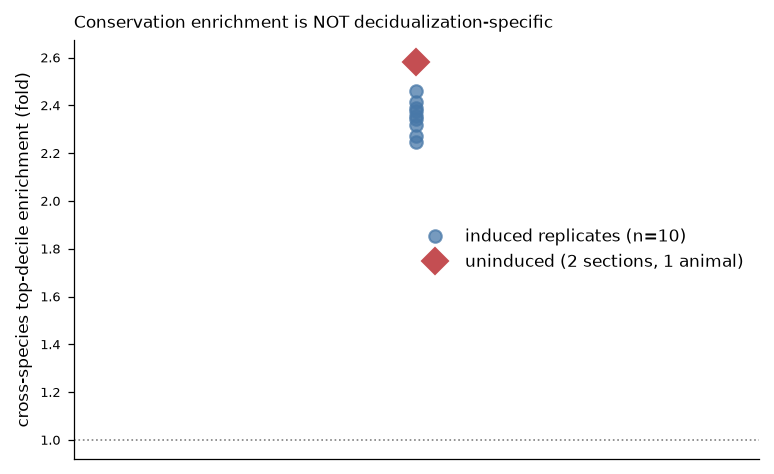

In [2]:
spec = J("specificity_control.json"); v = spec["verdict"]
print("DESIGN :", spec["design"]["coordinate"], "| matched n =", spec["design"]["n_matched"],
      "| universe =", spec["design"]["universe"])
print("CAVEAT :", spec["design"]["caveat"])
print()
print(f"uninduced fold           : {v['uninduced_fold']}")
print(f"induced fold (10 reps)   : {v['induced_fold_mean']} ± {spec['induced_summary']['fold_sd']}"
      f"  (range {spec['induced_summary']['fold_min']}–{spec['induced_summary']['fold_max']})")
print(f"ratio uninduced/induced  : {v['ratio']}   z vs induced reps: {v['uninduced_z_vs_induced_reps']}")
print(f"threshold-free rho       : uninduced {v['uninduced_rho']} vs induced mean {v['induced_rho_mean']}")
print()
print("READING:", spec["verdict"]["reading"])

folds = [r["fold"] for r in spec["induced_replicates"]]
fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.plot([0]*len(folds), folds, "o", color="#4878a8", alpha=0.75, label="induced replicates (n=10)")
ax.plot([0], [v["uninduced_fold"]], "D", color="#c44e52", ms=9, label="uninduced (2 sections, 1 animal)")
ax.axhline(1.0, color="grey", lw=0.8, ls=":")
ax.set_xlim(-0.6, 0.6); ax.set_xticks([])
ax.set_ylabel("cross-species top-decile enrichment (fold)")
ax.set_title("Conservation enrichment is NOT decidualization-specific")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()

The per-gene **rescue**: conservation being tissue-generic doesn't kill the result — it
re-scopes it. Nested sets isolate the genes whose conservation is decidualization-specific:

In [3]:
dsp = J("decidua_specific_report.json")
print("Per-gene rescue — nested decidualization-specific sets "
      f"(universe {dsp['design']['universe']}, matched n {dsp['design']['matched_n']}):\n")
for k, s in dsp["sets"].items():
    print(f"  {k:<32s} n={s['n']:<5d} top: {', '.join(s['top'][:8])}")
e = dsp["enrichment_of_B"]
print(f"\nSet B enrichment: observed {e['observed']} vs expected {e['expected']}"
      f" -> fold {e['fold']}, p = {e['p']:.2e}")

Per-gene rescue — nested decidualization-specific sets (universe 8372, matched n 3958):

  A_human_and_induced_top10        n=221   top: Kcnma1(gain=+0.1465,z=+14.3), Pde10a(gain=+0.1464,z=+11.2), Cped1(gain=+0.1345,z=+12.0), Sat1(gain=+0.1181,z=+7.9), Ror2(gain=+0.1169,z=+6.4), Sfrp4(gain=+0.1038,z=+9.4), Jarid2(gain=+0.1027,z=+5.4), Nampt(gain=+0.0968,z=+9.7)
  B_conserved_not_uninduced_top10  n=147   top: Cped1(gain=+0.1345,z=+12.0), Sat1(gain=+0.1181,z=+7.9), Ror2(gain=+0.1169,z=+6.4), Jarid2(gain=+0.1027,z=+5.4), Nampt(gain=+0.0968,z=+9.7), Pfkfb4(gain=+0.0949,z=+6.3), Txn1(gain=+0.0943,z=+6.6), Runx1(gain=+0.0919,z=+10.2)
  C_B_and_gain_z_gt2               n=115   top: Cped1(gain=+0.1345,z=+12.0), Sat1(gain=+0.1181,z=+7.9), Ror2(gain=+0.1169,z=+6.4), Jarid2(gain=+0.1027,z=+5.4), Nampt(gain=+0.0968,z=+9.7), Pfkfb4(gain=+0.0949,z=+6.3), Txn1(gain=+0.0943,z=+6.6), Runx1(gain=+0.0919,z=+10.2)
  D_C_and_uninduced_at_noise       n=37    top: Cped1(gain=+0.1345,z=+12.0), Jarid2(gain=+0.

> ### DECISION — §1 specificity control
> - [ ] **Approve** — frame conservation as tissue-level, with sets B (n=147) / D (n=37) as the decidualization-specific core
> - [ ] **Flag** — the uninduced caveat (2 sections, 1 animal) makes even the control untrustworthy — needs more uninduced tissue
>
> _Notes:_

## §2 Gene-level census — divergence outnumbers conservation
Verdicts over all 1:1 ortholog pairs (recomputed from the ranking TSV):

9550 1:1 ortholog pairs, verdict column 'verdict':

verdict
NOT_POSITIONAL             7606
HUMAN_ONLY                  746
MOUSE_ONLY                  720
CONSERVED_POSITIONAL        226
CONSERVED_UNCLEAR_SHAPE     157
INVERTED                     95

divergent (HUMAN_ONLY+MOUSE_ONLY+INVERTED) : 1561
conserved positional                        : 226
ratio divergent : conserved                 = 6.9 : 1


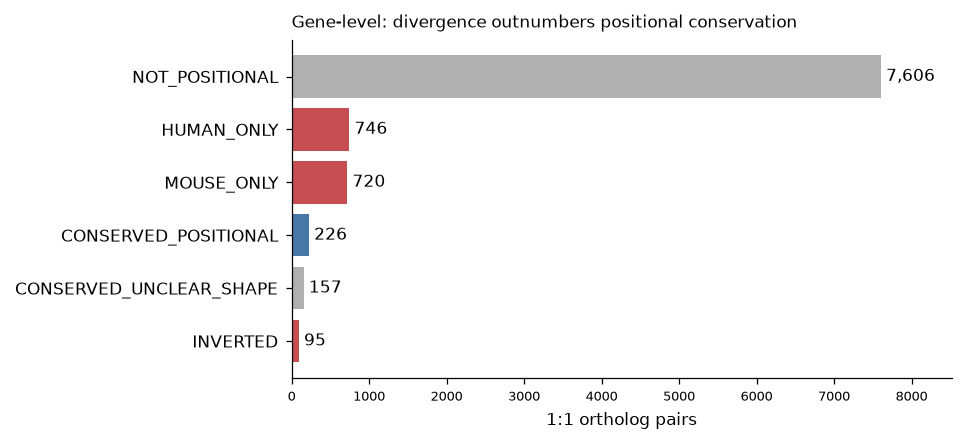

In [4]:
tsv = pd.read_csv(os.path.join(DATA, "conservation_ranking_all_genes.tsv"), sep="\t")
vc_col = [c for c in tsv.columns if "verdict" in c.lower()][0]
vc = tsv[vc_col].value_counts()
print(f"{len(tsv)} 1:1 ortholog pairs, verdict column '{vc_col}':\n")
print(vc.to_string())
div = int(vc.get("HUMAN_ONLY", 0) + vc.get("MOUSE_ONLY", 0) + vc.get("INVERTED", 0))
con = int(vc.get("CONSERVED_POSITIONAL", 0))
print(f"\ndivergent (HUMAN_ONLY+MOUSE_ONLY+INVERTED) : {div}")
print(f"conserved positional                        : {con}")
print(f"ratio divergent : conserved                 = {div/max(con,1):.1f} : 1")

order = vc.index.tolist()
fig, ax = plt.subplots(figsize=(6.4, 3.0))
colors = ["#c44e52" if k in ("HUMAN_ONLY","MOUSE_ONLY","INVERTED") else
          "#4878a8" if k=="CONSERVED_POSITIONAL" else "#b0b0b0" for k in order]
ax.barh(range(len(order))[::-1], vc.values, color=colors)
ax.set_yticks(range(len(order))[::-1]); ax.set_yticklabels(order, fontsize=8)
for i, val in zip(range(len(order))[::-1], vc.values):
    ax.text(val, i, f" {val:,}", va="center", fontsize=8)
ax.set_xlabel("1:1 ortholog pairs")
ax.set_title("Gene-level: divergence outnumbers positional conservation")
ax.margins(x=0.12)
fig.tight_layout()

> ### DECISION — §2 divergence:conservation ratio
> - [ ] **Approve** — report the ~7:1 divergent:conserved-positional ratio as a principal finding
> - [ ] **Flag** — verdict definitions need revisiting before quoting the ratio
>
> _Notes:_

## §3 Cross-species enrichment — the surviving positive
Top-decile MI overlap between species, on both coordinates:

In [5]:
cap = J("mi_capstone.json")
for ax_name in ("isodepth", "dpt"):
    x = cap[f"xspecies_{ax_name}"]
    print(f"cross-species top-decile overlap ({ax_name:9s}): {x['overlap']} / expected {x['expected']}"
          f" -> fold {x['fold']}, p = {x['p']:.1e}   (universe {x['universe']})")
print()
for sp in ("human", "mouse"):
    for ax_name in ("dpt", "isodepth"):
        print(f"{sp:6s} {ax_name:9s}: {cap[f'{sp}_{ax_name}_sig']:,} / {cap[f'{sp}_{ax_name}_n']:,} genes significant")
print("\nhuman dpt-vs-isodepth top-decile agreement:",
      f"{cap['human_dpt_vs_isodepth']['frac']:.3f} (overlap {cap['human_dpt_vs_isodepth']['overlap']})")

cross-species top-decile overlap (isodepth ): 402 / expected 138.5 -> fold 2.9, p = 3.7e-101   (universe 13867)
cross-species top-decile overlap (dpt      ): 399 / expected 136.9 -> fold 2.91, p = 3.8e-101   (universe 13708)

human  dpt      : 6,926 / 28,499 genes significant
human  isodepth : 4,567 / 28,499 genes significant
mouse  dpt      : 14,382 / 22,645 genes significant
mouse  isodepth : 12,968 / 23,429 genes significant

human dpt-vs-isodepth top-decile agreement: 0.631 (overlap 1799)


> ### DECISION — §3 cross-species enrichment
> - [ ] **Approve** — quote fold 2.90/2.91 (isodepth/pseudotime) as the core conservation statistic
> - [ ] **Flag** — needs the missing cutoff-dependence control re-run first (§10)
>
> _Notes:_

## §4 Coordinate transfer by timepoint
Transfer of the spatial coordinate across species, per reference phase and mouse timepoint
(from `transfer_results.csv`). This is the section behind your transfer worry — see also
notebook 03 §Q1 for the three-number reconciliation.

    phase      stage  rho_all_hm  rho_all_mh  rho_dec_hm  n_dec_mh  p_hm
secretory  uninduced       0.190       0.034       0.259         9 0.050
secretory 1dpi_early       0.525       0.686       0.118       638 0.005
secretory  1dpi_late       0.286       0.372      -0.290      2955 0.005
secretory       2dpi       0.596       0.656       0.508      1206 0.005
secretory       3dpi       0.346       0.524       0.492      5449 0.005
secretory       4dpi      -0.151      -0.060      -0.018      3754 0.184
menstrual  uninduced       0.008      -0.006      -0.029         9 0.965
menstrual 1dpi_early       0.604       0.679       0.407       638 0.005
menstrual  1dpi_late       0.050       0.273      -0.117      2954 0.498
menstrual       2dpi       0.705       0.635       0.602      1206 0.005
menstrual       3dpi       0.659       0.764       0.571      5449 0.005
menstrual       4dpi       0.425       0.505       0.189      3750 0.005

NOTE uninduced/menstrual: rho ~ 0 (p=0.97); mouse 

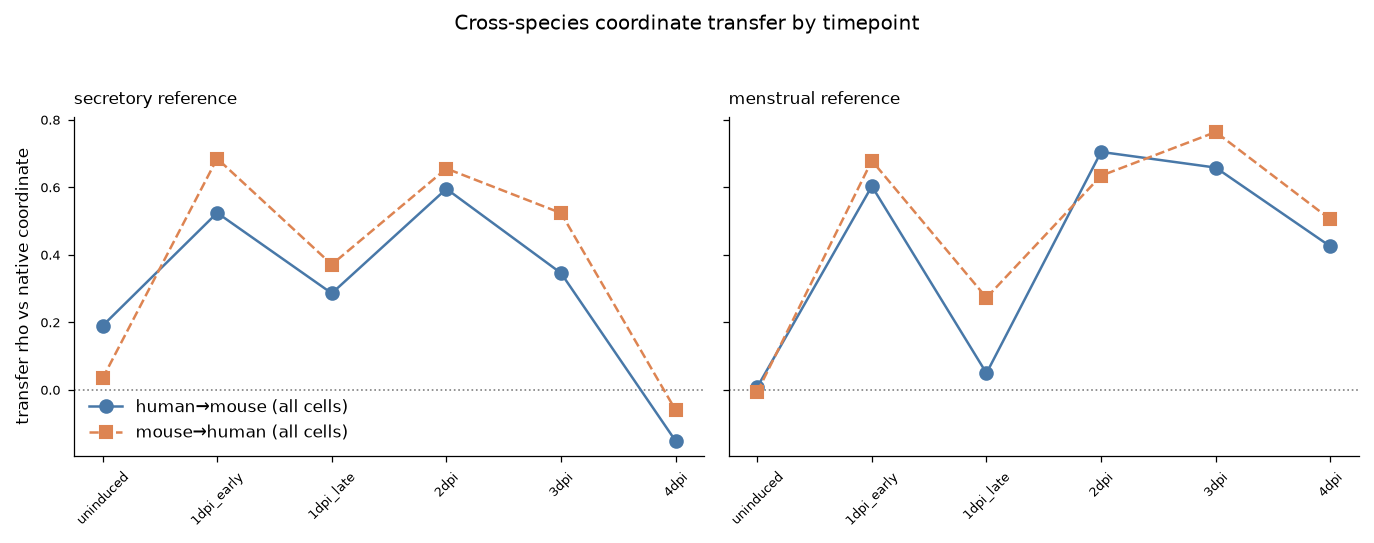

In [6]:
tr = pd.read_csv(os.path.join(DATA, "transfer_results.csv"))
stages = ["uninduced","1dpi_early","1dpi_late","2dpi","3dpi","4dpi"]
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.4), sharey=True)
for ax, phase in zip(axes, ["secretory","menstrual"]):
    d = tr[tr.phase==phase].set_index("stage").reindex(stages)
    ax.axhline(0, color="grey", lw=0.8, ls=":")
    ax.plot(stages, d.rho_all_hm, "o-", color="#4878a8", label="human→mouse (all cells)")
    ax.plot(stages, d.rho_all_mh, "s--", color="#dd8452", label="mouse→human (all cells)")
    ax.set_title(f"{phase} reference"); ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("transfer rho vs native coordinate")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Cross-species coordinate transfer by timepoint", y=1.04)
fig.tight_layout()

print(tr[["phase","stage","rho_all_hm","rho_all_mh","rho_dec_hm","n_dec_mh","p_hm"]]
      .round(3).to_string(index=False))
print()
print("NOTE uninduced/menstrual: rho ~ 0 (p=0.97); mouse uninduced has only 9 decidual cells.")
print("NOTE 4dpi: in the FULL object transfer rho is 0.207 — degraded, NOT inverted (verify README).")
print("     The negative (-0.151) appears only in this table's isolated single-timepoint secretory")
print("     fit. The compartment-level Simpson reversal (next section) is the menstrual x 4dpi pairing.")

> ### DECISION — §4 per-timepoint transfer
> - [ ] **Approve** — present transfer as timepoint-resolved (strong 2–3 dpi, degraded 4dpi, absent uninduced) — no single pooled number
> - [ ] **Flag** — hold all transfer claims until the reconciliation in notebook 03 §Q1 is settled
>
> _Notes:_

## §5 The 4dpi failure is a Simpson reversal — excluded, not patched
Compartment structure inverts under transfer at menstrual×4dpi; the control pairing does not.

In [7]:
sim = J("simpson_check.json")
for pairing in ("menstrual_x_4dpi", "secretory_x_1dpi_late"):
    s = sim[pairing]
    print(f"== {pairing} ==")
    print(f"  native compartment gap      : {s['native_gap']}")
    print(f"  transferred compartment gap : {s['transferred_gap']}   inverted: {s['compartment_inverted']}")
    print(f"  pooled rho                  : {s['pooled_rho']}")
    print(f"  edge mass onto human FIB    : from mouse dec {s['edgemass_onto_endometrial_fibroblast']['from_mouse_dec']:.3f}"
          f" / from mouse fib {s['edgemass_onto_endometrial_fibroblast']['from_mouse_fib']:.3f}")
    print(f"  edge mass onto human DEC    : from mouse dec {s['edgemass_onto_decidual_cell']['from_mouse_dec']:.3f}"
          f" / from mouse fib {s['edgemass_onto_decidual_cell']['from_mouse_fib']:.3f}")
    print()

== menstrual_x_4dpi ==
  native compartment gap      : 0.411
  transferred compartment gap : -0.074   inverted: True
  pooled rho                  : 0.1211
  edge mass onto human FIB    : from mouse dec 0.322 / from mouse fib 0.261
  edge mass onto human DEC    : from mouse dec 0.677 / from mouse fib 0.739

== secretory_x_1dpi_late ==
  native compartment gap      : 0.215
  transferred compartment gap : 0.4538   inverted: False
  pooled rho                  : 0.6268
  edge mass onto human FIB    : from mouse dec 0.335 / from mouse fib 0.958
  edge mass onto human DEC    : from mouse dec 0.665 / from mouse fib 0.041



> ### DECISION — §5 4dpi exclusion
> - [ ] **Approve** — exclude 4dpi from transfer-based claims with the Simpson-reversal evidence as stated
> - [ ] **Flag** — attempt a repair (e.g. compartment-stratified transfer) instead of exclusion
>
> _Notes:_

## §6 Rewiring, not heterochrony — peak-displacement on two axes
Median displacement is 0 (isodepth) / 1 (pseudotime) bin, but a third of genes move ≥5 bins;
the two axes agree on which (ρ 0.73). Tails are asymmetric (README: −9→17 genes, +9→36) —
do **not** quote symmetric tails.

In [8]:
dp = J("dpeak_two_axes.json")
for axname in ("isodepth_axis", "pseudotime_axis"):
    d = dp[axname]
    print(f"{axname:16s}: n={d['n']}, median dpeak {d['median']}, mean {d['mean']}, sd {d['sd']},"
          f" frac|dpeak|<=1 {d['frac_le1']:.3f}, frac>=5 {d['frac_ge5']:.3f}, Wilcoxon p {d['wilcoxon_p']:.1e}")
a = dp["agreement"]
print(f"\ntwo-axis agreement: spearman {a['spearman_dpeak_iso_vs_pt']}, same sign {a['frac_same_sign']:.3f},"
      f" both displaced {a['frac_both_displaced']:.3f}, both matched {a['frac_both_matched']:.3f}")

isodepth_axis   : n=478, median dpeak 0.0, mean 1.056, sd 4.363, frac|dpeak|<=1 0.416, frac>=5 0.331, Wilcoxon p 3.6e-07
pseudotime_axis : n=478, median dpeak 1.0, mean 1.345, sd 3.924, frac|dpeak|<=1 0.389, frac>=5 0.310, Wilcoxon p 1.7e-13

two-axis agreement: spearman 0.732, same sign 0.697, both displaced 0.226, both matched 0.291


> ### DECISION — §6 dpeak / rewiring
> - [ ] **Approve** — report 'conserved position for most, large displacement for a third' with asymmetric tails
> - [ ] **Flag** — displacement metric needs a null model before quoting fractions
>
> _Notes:_

## §7 MI is not redundant with correlation
Justifies the MI estimator: moderate rank agreement with |ρ|, and the MI-only genes are
enriched for non-monotone (quadratic) profiles.

In [9]:
red = J("mi_vs_rho_redundancy.json")
for sp in ("mouse", "human"):
    r = red[sp]
    print(f"{sp:6s}: rho(MI, |rho|) = {r['rho_MI_vs_absrho']}, top-decile overlap {r['frac_overlap']:.3f},"
          f" MI-only genes {r['n_mi_only']} (median |quad| {r['mi_only_median_abs_quad']}"
          f" vs shared {r['shared_median_abs_quad']})")
print(f"\nconserved by MI: {red['conserved_by_MI']} | by |rho|: {red['conserved_by_absrho']}"
      f" | Jaccard {red['conserved_jaccard']} | MI-unique conserved: {red['n_MI_unique_conserved']}")
print("MI-unique examples:", ", ".join(red["MI_unique_conserved"][:10]))

mouse : rho(MI, |rho|) = 0.433, top-decile overlap 0.468, MI-only genes 651 (median |quad| 0.0578 vs shared 0.0303)
human : rho(MI, |rho|) = 0.469, top-decile overlap 0.560, MI-only genes 554 (median |quad| 0.0462 vs shared 0.0347)

conserved by MI: 201 | by |rho|: 178 | Jaccard 0.223 | MI-unique conserved: 132
MI-unique examples: Abi3bp, Acss3, Adam10, Adam12, Adamts2, Adgrl3, Agap1, Ank2, Ank3, Ano1


> ### DECISION — §7 MI vs correlation
> - [ ] **Approve** — keep MI as the primary statistic; cite Jaccard 0.223 + non-monotone excess as justification
> - [ ] **Flag** — switch primary statistic to |rho| for interpretability
>
> _Notes:_

## §8 Homology model comparison
Enrichment under three homology maps — Ensembl 1:1 is the cleanest; SAMap graphs are
paralog-dominated and dilute the signal (this motivated 'vanilla SAMap = primary arm').

In [10]:
hom = J("homology_model_comparison.json")
print(f"{'model':14s} {'links':>8s} {'both':>6s} {'expected':>9s} {'fold':>6s} {'paralog frac':>13s}")
for k, h in hom.items():
    print(f"{k:14s} {h['n_links']:8,d} {h['both']:6,d} {h['expected']:9.1f} {h['fold']:6.3f}"
          f" {h['paralog_frac']:13.3f}")
print("\nEnsembl 1:1 orthology gives the cleanest cross-species signal (fold 3.11);")
print("SAMap graphs are paralog-dominated (95.5–97.8%) and dilute enrichment.")

model             links   both  expected   fold  paralog frac
ensembl_1to1      9,550    477     153.3  3.112         0.000
samap_blast     190,472  3,943    2126.1  1.855         0.955
samap_hmmer     228,212  4,976    3427.7  1.452         0.978

Ensembl 1:1 orthology gives the cleanest cross-species signal (fold 3.11);
SAMap graphs are paralog-dominated (95.5–97.8%) and dilute enrichment.


> ### DECISION — §8 homology model
> - [ ] **Approve** — use Ensembl 1:1 for gene-level claims; SAMap graphs only for integration/embedding
> - [ ] **Flag** — paralog-aware analysis should be a main-text arm, not a comparison
>
> _Notes:_

## §9 Isodepth ↔ pseudotime agreement (and where 0.591 comes from)
Within-species agreement of the two coordinates, and the transferred-vs-native isodepth
correlation whose overall value (0.591) is one of the three unreconciled transfer numbers.

In [11]:
ipt = J("isodepth_pt_correlation.json")
for k in ("human_isodepth_vs_dpt", "mouse_isodepth_vs_dpt", "mouse_native_iso_vs_transferred_iso"):
    d = ipt[k]
    print(f"{k:36s}: spearman {d['spearman']:.3f} (n={d['n']:,})")
    for g, gv in d["per_group"].items():
        try: print(f"    {g:14s} spearman {gv['spearman']:.3f} (n={gv.get('n','?'):,})")
        except Exception: print(f"    {g:14s} {gv}")
    print()

human_isodepth_vs_dpt               : spearman 0.671 (n=47,533)
    secretory      spearman 0.551 (n=23,441)
    menstrual      spearman 0.795 (n=24,092)

mouse_isodepth_vs_dpt               : spearman 0.690 (n=32,957)
    1_dpi_early    spearman 0.791 (n=2,686)
    1_dpi_late     spearman 0.606 (n=10,656)
    2_dpi          spearman 0.787 (n=3,524)
    3_dpi          spearman 0.840 (n=10,649)
    4_dpi_bleeding spearman 0.797 (n=5,442)

mouse_native_iso_vs_transferred_iso : spearman 0.591 (n=43,183)
    uninduced      spearman 0.711 (n=9,334)
    1_dpi_early    spearman 0.583 (n=2,688)
    1_dpi_late     spearman 0.596 (n=10,787)
    2_dpi          spearman 0.702 (n=3,571)
    3_dpi          spearman 0.793 (n=10,664)
    4_dpi_bleeding spearman 0.207 (n=6,139)



> ### DECISION — §9 coordinate agreement
> - [ ] **Approve** — quote within-species agreement (~0.67/0.69) as coordinate validation
> - [ ] **Flag** — per-group heterogeneity too large to summarize with one number
>
> _Notes:_

## §10 Missing control artifacts — cannot re-verify
`cutoff_dependence.json` and `rrho_permutation_null.json` are cited by the handoff but the
files **do not exist** anywhere under the repo, `decidualization/revisions`, or netscratch
(exhaustive overnight search). Their numbers survive only in the prior session's printed
output — currently **unverifiable**.

> ### DECISION — §10 missing controls
> - [ ] **Approve re-run** — regenerate both controls as config-driven verify additions (session can do this; needs your go for the compute)
> - [ ] **Accept transcript numbers** — quote with an 'unverified' footnote
> - [ ] **Drop** — remove both from the narrative
>
> _Notes:_

## §11 Overnight verify-suite re-execution — 1 mismatch, now explained
All 7 notebooks re-executed cleanly on the cluster (job `64356844`, eddy partition;
7 checks in nb05, 1 MISMATCH, everything else green).

The single mismatch — **"raw-counts predecessor preserved: recomputed=False, recorded=True"** —
is **self-inflicted and benign**: the check looks for
`workflow/scripts/prep_samap_input.py.raw_counts.bak`, which is one of the 10 backup-litter
files the cleanup pass moved to the attic (`_scratch/cleanup_20260901/scripts/`). The file is
intact there; the verify check just points at the old path. Fix is one line in nb05 (point the
check at the attic path) — or revert change 1 for that one file.

> ### DECISION — §11 verify suite
> - [ ] **Approve** — suite is green; update the nb05 check to the attic path
> - [ ] **Prefer restore** — copy that one file back to workflow/scripts/ instead
>
> _Notes:_